# Inventory Replenishment Agent

This notebook builds and evaluates an inventory replenishment agent for multiple SKUs.

The workflow is:

1. Generate and load daily sales, opening inventory, and SKU policy/cost CSV files.
2. Aggregate demand by date and SKU.
3. Forecast demand with an exponentially weighted moving average (EWMA).
4. Estimate forecast error and safety stock using the requested service level.
5. Simulate a daily reorder-point/order-up-to policy with lead times and a PO pipeline.
6. Report stockouts, fill rate, holding cost, stockout cost, order cost, and total cost.
7. Print a daily decision log with the rationale for every action.

The data is synthetic so the notebook runs end-to-end in Colab without requiring an external file upload. The same code can be used with real CSVs that follow the assignment schemas.

In [1]:
# Imports and reproducibility
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from math import ceil

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 120)

rng = np.random.default_rng(42)
DATA_DIR = Path('inventory_agent_data')
DATA_DIR.mkdir(exist_ok=True)


## 1. Create the input CSV files

The assignment requires three schemas:

- `sales.csv`: `date, sku, qty_sold`
- `inventory.csv`: `sku, opening_stock`
- `params.csv`: `sku, unit_cost, holding_cost_per_day, stockout_cost, lead_time_days, min_order_qty, service_level`

The generator creates 90 days of demand for three SKUs with trend, weekly seasonality, and random variation. It then writes the files so they can be inspected or replaced with real data.

In [2]:
# Generate 90 days of realistic synthetic sales for three SKUs
dates = pd.date_range('2026-01-01', periods=90, freq='D')
sku_settings = {
    'SKU-A': {'base': 18, 'trend': 0.035, 'seasonality': 4.0},
    'SKU-B': {'base': 10, 'trend': 0.020, 'seasonality': 2.5},
    'SKU-C': {'base': 6,  'trend': 0.015, 'seasonality': 1.8},
}

sales_rows = []
for sku, s in sku_settings.items():
    for t, date in enumerate(dates):
        weekly = s['seasonality'] * (1 + np.sin(2 * np.pi * date.dayofweek / 7)) / 2
        expected = s['base'] + s['trend'] * t + weekly
        qty = max(0, int(rng.poisson(expected)))
        sales_rows.append({'date': date, 'sku': sku, 'qty_sold': qty})

sales_generated = pd.DataFrame(sales_rows)
inventory_generated = pd.DataFrame({
    'sku': ['SKU-A', 'SKU-B', 'SKU-C'],
    'opening_stock': [105, 70, 48]
})
params_generated = pd.DataFrame({
    'sku': ['SKU-A', 'SKU-B', 'SKU-C'],
    'unit_cost': [12.00, 8.00, 20.00],
    'holding_cost_per_day': [0.08, 0.06, 0.12],
    'stockout_cost': [18.00, 14.00, 30.00],
    'lead_time_days': [4, 5, 3],
    'min_order_qty': [30, 25, 18],
    'service_level': [0.95, 0.90, 0.95]
})

sales_generated.to_csv(DATA_DIR / 'sales.csv', index=False)
inventory_generated.to_csv(DATA_DIR / 'inventory.csv', index=False)
params_generated.to_csv(DATA_DIR / 'params.csv', index=False)

print(f'Created input files in {DATA_DIR.resolve()}')
display(sales_generated.head())
display(inventory_generated)
display(params_generated)


Created input files in /content/inventory_agent_data


,date,sku,qty_sold
0,2026-01-01,SKU-A,25
1,2026-01-02,SKU-A,13
2,2026-01-03,SKU-A,20
3,2026-01-04,SKU-A,18
4,2026-01-05,SKU-A,21


,sku,opening_stock
0,SKU-A,105
1,SKU-B,70
2,SKU-C,48


,sku,unit_cost,holding_cost_per_day,stockout_cost,lead_time_days,min_order_qty,service_level
0,SKU-A,12.0,0.08,18.0,4,30,0.95
1,SKU-B,8.0,0.06,14.0,5,25,0.90
2,SKU-C,20.0,0.12,30.0,3,18,0.95


## 2. Load, validate, and aggregate the data

In [3]:
sales = pd.read_csv(DATA_DIR / 'sales.csv', parse_dates=['date'])
inventory = pd.read_csv(DATA_DIR / 'inventory.csv')
params = pd.read_csv(DATA_DIR / 'params.csv')

required_sales = {'date', 'sku', 'qty_sold'}
required_inventory = {'sku', 'opening_stock'}
required_params = {'sku', 'unit_cost', 'holding_cost_per_day', 'stockout_cost', 'lead_time_days', 'min_order_qty', 'service_level'}
assert required_sales.issubset(sales.columns)
assert required_inventory.issubset(inventory.columns)
assert required_params.issubset(params.columns)
assert sales['qty_sold'].ge(0).all()
assert params['service_level'].between(0.50, 0.999).all()

# Aggregate in case the source file contains multiple sales rows per SKU/date.
daily_demand = (sales.groupby(['date', 'sku'], as_index=False)['qty_sold'].sum())
all_dates = pd.date_range(daily_demand['date'].min(), daily_demand['date'].max(), freq='D')
all_skus = sorted(params['sku'].unique())
calendar = pd.MultiIndex.from_product([all_dates, all_skus], names=['date', 'sku']).to_frame(index=False)
daily_demand = calendar.merge(daily_demand, on=['date', 'sku'], how='left').fillna({'qty_sold': 0})
daily_demand['qty_sold'] = daily_demand['qty_sold'].astype(int)

print('Rows after daily aggregation:', len(daily_demand))
display(daily_demand.head(9))
display(daily_demand.groupby('sku')['qty_sold'].agg(['count', 'mean', 'std', 'sum']).round(2))


Rows after daily aggregation: 270


,date,sku,qty_sold
0,2026-01-01,SKU-A,25
1,2026-01-01,SKU-B,11
2,2026-01-01,SKU-C,13
3,2026-01-02,SKU-A,13
4,2026-01-02,SKU-B,8
5,2026-01-02,SKU-C,6
6,2026-01-03,SKU-A,20
7,2026-01-03,SKU-B,11
8,2026-01-03,SKU-C,4


,count,mean,std,sum
sku,,,,
SKU-A,90,21.11,4.92,1900
SKU-B,90,12.27,3.69,1104
SKU-C,90,7.46,3.01,671


## 3. EWMA forecast and safety stock

For each SKU, the forecast for day *t* is the EWMA of demand observed through day *t-1*, so the simulation does not use future demand. The forecast error standard deviation is estimated from the historical one-step-ahead EWMA errors. Safety stock is:

\[
SS = z_{service\ level} 	imes \sigma_{error} 	imes \sqrt{lead\ time}
\]

The reorder point is expected lead-time demand plus safety stock. A higher service level produces a larger z-score and therefore more protection against stockouts.

In [4]:
# Forecast every SKU one day ahead using EWMA.
ALPHA = 0.30
forecast_rows = []
for sku in all_skus:
    sku_df = daily_demand[daily_demand['sku'] == sku].sort_values('date').copy()
    # shift(1) ensures the forecast for today only uses information available yesterday.
    sku_df['forecast'] = sku_df['qty_sold'].shift(1).ewm(alpha=ALPHA, adjust=False, min_periods=1).mean()
    sku_df['forecast'] = sku_df['forecast'].bfill()
    sku_df['forecast_error'] = sku_df['qty_sold'] - sku_df['forecast']
    forecast_rows.append(sku_df)

forecast_df = pd.concat(forecast_rows, ignore_index=True)
error_stats = (forecast_df.groupby('sku')['forecast_error']
               .agg(error_std=lambda x: float(x.std(ddof=1)), mae=lambda x: float(np.abs(x).mean()))
               .reset_index())

policy = params.merge(error_stats, on='sku', how='left')
policy['z_value'] = policy['service_level'].apply(lambda sl: {0.90: 1.2816, 0.95: 1.6449}.get(round(sl, 2), 1.6449))
policy['avg_daily_demand'] = forecast_df.groupby('sku')['forecast'].mean().values
policy['lead_time_demand'] = policy['avg_daily_demand'] * policy['lead_time_days']
policy['safety_stock'] = policy['z_value'] * policy['error_std'] * np.sqrt(policy['lead_time_days'])
policy['reorder_point'] = policy['lead_time_demand'] + policy['safety_stock']
policy['review_period_days'] = 1
policy['order_up_to'] = policy['reorder_point'] + policy['avg_daily_demand'] * policy['review_period_days']

display(policy.round(2))


,sku,unit_cost,holding_cost_per_day,stockout_cost,lead_time_days,min_order_qty,service_level,error_std,mae,z_value,avg_daily_demand,lead_time_demand,safety_stock,reorder_point,review_period_days,order_up_to
0,SKU-A,12.0,0.08,18.0,4,30,0.95,5.42,4.38,1.64,21.12,84.48,17.83,102.31,1,123.43
1,SKU-B,8.0,0.06,14.0,5,25,0.90,3.90,3.09,1.28,12.18,60.91,11.18,72.10,1,84.28
2,SKU-C,20.0,0.12,30.0,3,18,0.95,3.32,2.67,1.64,7.69,23.06,9.46,32.52,1,40.21


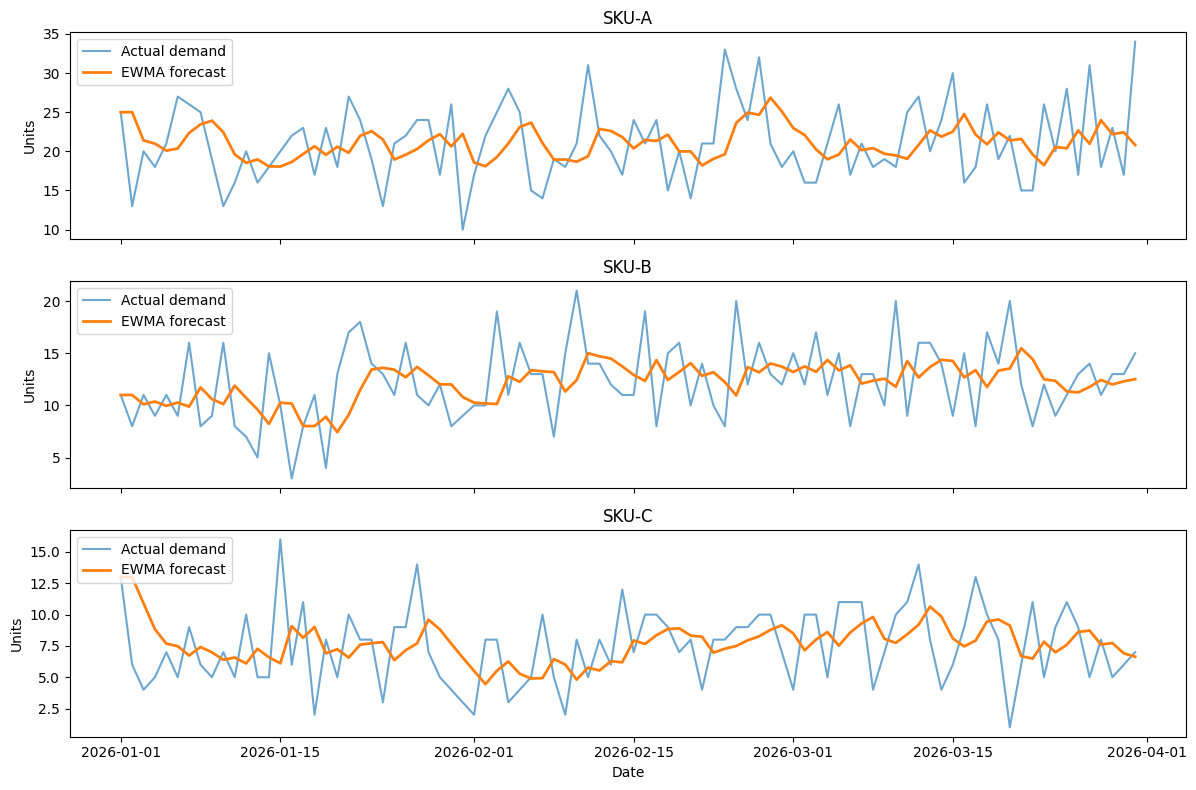

In [5]:
# Visualize actual demand and one-step-ahead EWMA forecasts
fig, axes = plt.subplots(len(all_skus), 1, figsize=(12, 8), sharex=True)
if len(all_skus) == 1:
    axes = [axes]
for ax, sku in zip(axes, all_skus):
    temp = forecast_df[forecast_df['sku'] == sku]
    ax.plot(temp['date'], temp['qty_sold'], label='Actual demand', alpha=0.65)
    ax.plot(temp['date'], temp['forecast'], label='EWMA forecast', linewidth=2)
    ax.set_title(sku)
    ax.set_ylabel('Units')
    ax.legend(loc='upper left')
plt.xlabel('Date')
plt.tight_layout()
plt.show()


## 4. Replenishment agent and simulation

The agent reviews each SKU every day. It calculates inventory position as:

`on hand + inventory in transit - backorders`

It projects inventory over the lead time plus the one-day review period. If projected inventory is at or below the reorder point, it orders enough to reach the order-up-to level, rounded up to the SKU's minimum order quantity. Otherwise, it waits to avoid unnecessary holding cost.

Demand is fulfilled from on-hand inventory first. Unfilled demand becomes a same-day stockout quantity. POs arrive after the SKU-specific lead time. Costs are tracked as holding cost, stockout cost, variable order cost, and a fixed PO cost of zero as allowed by the prompt.

In [6]:
# Simulation helpers
def ceil_to_multiple(quantity, minimum):
    if quantity <= 0:
        return 0
    return int(max(minimum, ceil(quantity / minimum) * minimum))

def run_simulation(demand_df, inventory_df, policy_df, fixed_po_cost=0.0):
    demand_lookup = {(row.date, row.sku): int(row.qty_sold) for row in demand_df.itertuples()}
    inventory_map = inventory_df.set_index('sku')['opening_stock'].to_dict()
    pmap = policy_df.set_index('sku').to_dict('index')
    dates = sorted(demand_df['date'].unique())
    skus = sorted(policy_df['sku'].unique())
    state = {sku: {'on_hand': float(inventory_map[sku]), 'backorders': 0.0, 'pipeline': {}} for sku in skus}
    logs, metrics = [], []

    for date in dates:
        date = pd.Timestamp(date)
        for sku in skus:
            p = pmap[sku]
            s = state[sku]
            arrivals = float(s['pipeline'].pop(date, 0.0))
            s['on_hand'] += arrivals
            demand = demand_lookup[(date, sku)]
            forecast_row = demand_df[(demand_df['date'] == date) & (demand_df['sku'] == sku)].iloc[0]
            forecast = float(forecast_row['forecast'])
            inv_before = s['on_hand']
            fulfilled = min(s['on_hand'], demand + s['backorders'])
            s['on_hand'] -= fulfilled
            unfilled = demand + s['backorders'] - fulfilled
            s['backorders'] = unfilled

            pipeline_units = sum(s['pipeline'].values())
            inventory_position = s['on_hand'] + pipeline_units - s['backorders']
            projection_horizon = int(p['lead_time_days'] + p['review_period_days'])
            projected_demand = forecast * projection_horizon
            projected_inventory = inventory_position - projected_demand
            target = p['order_up_to']

            if projected_inventory <= p['reorder_point'] or inventory_position <= p['reorder_point']:
                raw_order = max(0.0, target - inventory_position)
                order_qty = ceil_to_multiple(raw_order, int(p['min_order_qty']))
                action = f'PLACE PO ({order_qty} units)' if order_qty else 'WAIT (target already met)'
                rationale = (f'Projected inventory {projected_inventory:.1f} <= reorder point {p["reorder_point"]:.1f}; '
                             f'order up to {target:.1f}, rounded to minimum order quantity {int(p["min_order_qty"])}.') if order_qty else                             'Inventory position already covers the order-up-to target.'
                if order_qty:
                    arrival_date = date + pd.Timedelta(days=int(p['lead_time_days']))
                    s['pipeline'][arrival_date] = s['pipeline'].get(arrival_date, 0.0) + order_qty
            else:
                order_qty = 0
                action = 'WAIT'
                rationale = (f'Projected inventory {projected_inventory:.1f} is above reorder point {p["reorder_point"]:.1f}; '
                             'wait to reduce excess holding cost.')

            holding_cost = s['on_hand'] * p['holding_cost_per_day']
            stockout_cost = unfilled * p['stockout_cost']
            order_cost = (fixed_po_cost + order_qty * p['unit_cost']) if order_qty else 0.0
            metrics.append({'date': date, 'sku': sku, 'demand': demand, 'fulfilled': fulfilled,
                            'unfilled': unfilled, 'holding_cost': holding_cost,
                            'stockout_cost': stockout_cost, 'order_cost': order_cost,
                            'order_qty': order_qty})
            logs.append({'date': date, 'sku': sku, 'opening_on_hand': inv_before,
                         'arrivals': arrivals, 'demand': demand, 'forecast': forecast,
                         'fulfilled': fulfilled, 'stockout_units': unfilled,
                         'on_hand_end': s['on_hand'], 'backorders_end': s['backorders'],
                         'pipeline_after_decision': sum(s['pipeline'].values()),
                         'inventory_position': inventory_position,
                         'projected_inventory': projected_inventory,
                         'reorder_point': p['reorder_point'], 'order_up_to': target,
                         'action': action, 'rationale': rationale})

    log_df = pd.DataFrame(logs)
    metric_df = pd.DataFrame(metrics)
    total_demand = metric_df['demand'].sum()
    total_fulfilled = metric_df['fulfilled'].sum()
    summary = {
        'total_demand': total_demand,
        'fulfilled_units': total_fulfilled,
        'stockout_units': metric_df['unfilled'].sum(),
        'stockout_days': int((metric_df['unfilled'] > 0).sum()),
        'fill_rate': total_fulfilled / total_demand if total_demand else 1.0,
        'holding_cost': metric_df['holding_cost'].sum(),
        'stockout_cost': metric_df['stockout_cost'].sum(),
        'order_cost': metric_df['order_cost'].sum(),
        'total_cost': metric_df[['holding_cost', 'stockout_cost', 'order_cost']].sum().sum(),
        'number_of_pos': int((metric_df['order_qty'] > 0).sum()),
    }
    return log_df, metric_df, summary

log_df, metric_df, summary = run_simulation(forecast_df, inventory, policy, fixed_po_cost=0.0)


## 5. Baseline comparison

To measure whether the agent adds value, the baseline uses a simple fixed rule: it forecasts each SKU at its historical average, carries no forecast-error safety stock, and orders to cover average demand over the lead time plus one review day. Both strategies use the same opening inventory, lead times, minimum order quantities, and cost assumptions.

In [7]:
# Fixed-average baseline: no EWMA update and no safety-stock buffer.
baseline_policy = policy.copy()
baseline_policy['safety_stock'] = 0.0
baseline_policy['reorder_point'] = baseline_policy['avg_daily_demand'] * baseline_policy['lead_time_days']
baseline_policy['order_up_to'] = baseline_policy['reorder_point'] + baseline_policy['avg_daily_demand']
baseline_forecast_df = forecast_df.copy()
avg_forecast_map = baseline_policy.set_index('sku')['avg_daily_demand'].to_dict()
baseline_forecast_df['forecast'] = baseline_forecast_df['sku'].map(avg_forecast_map)

baseline_log, baseline_metric_df, baseline_summary = run_simulation(
    baseline_forecast_df, inventory, baseline_policy, fixed_po_cost=0.0
)

comparison = pd.DataFrame([
    {'policy': 'Fixed-average baseline', **baseline_summary},
    {'policy': 'EWMA replenishment agent', **summary}
]).set_index('policy')
display(comparison[['fill_rate', 'stockout_units', 'stockout_days', 'holding_cost', 'stockout_cost', 'order_cost', 'total_cost', 'number_of_pos']].round(2))

agent_vs_baseline = {
    'fill_rate_change_percentage_points': (summary['fill_rate'] - baseline_summary['fill_rate']) * 100,
    'total_cost_change': summary['total_cost'] - baseline_summary['total_cost'],
    'stockout_units_change': summary['stockout_units'] - baseline_summary['stockout_units']
}
print('Agent minus baseline:')
display(pd.DataFrame([agent_vs_baseline]))


,fill_rate,stockout_units,stockout_days,holding_cost,stockout_cost,order_cost,total_cost,number_of_pos
policy,,,,,,,,
Fixed-average baseline,1.0,0.0,0,596.92,0.0,45360.0,45956.92,146
EWMA replenishment agent,1.0,0.0,0,875.50,0.0,45360.0,46235.50,144


Agent minus baseline:


,fill_rate_change_percentage_points,total_cost_change,stockout_units_change
0,0.0,278.58,0.0


## 5. Results and evaluation

In [8]:
summary_df = pd.DataFrame([summary], dtype=object).T.rename(columns={0: 'value'})
summary_df.loc['fill_rate', 'value'] = f"{summary['fill_rate']:.2%}"
summary_df.loc['holding_cost', 'value'] = f"${summary['holding_cost']:,.2f}"
summary_df.loc['stockout_cost', 'value'] = f"${summary['stockout_cost']:,.2f}"
summary_df.loc['order_cost', 'value'] = f"${summary['order_cost']:,.2f}"
summary_df.loc['total_cost', 'value'] = f"${summary['total_cost']:,.2f}"
display(summary_df)

per_sku = (metric_df.groupby('sku').agg(
    demand=('demand', 'sum'), fulfilled=('fulfilled', 'sum'), stockout_units=('unfilled', 'sum'),
    fill_rate=('fulfilled', lambda x: x.sum() / metric_df.loc[x.index, 'demand'].sum()),
    holding_cost=('holding_cost', 'sum'), stockout_cost=('stockout_cost', 'sum'),
    order_cost=('order_cost', 'sum'), purchase_orders=('order_qty', lambda x: (x > 0).sum()))
    .reset_index())
display(per_sku.round(3))


,value
total_demand,3675
fulfilled_units,3675.0
stockout_units,0.0
stockout_days,0
fill_rate,100.00%
holding_cost,$875.50
stockout_cost,$0.00
order_cost,"$45,360.00"
total_cost,"$46,235.50"
number_of_pos,144


,sku,demand,fulfilled,stockout_units,fill_rate,holding_cost,stockout_cost,order_cost,purchase_orders
0,SKU-A,1900,1900.0,0.0,1.0,390.88,0.0,23040.0,63
1,SKU-B,1104,1104.0,0.0,1.0,189.66,0.0,9000.0,44
2,SKU-C,671,671.0,0.0,1.0,294.96,0.0,13320.0,37


In [9]:
# Daily agent log: every SKU/day has an action and an explanation.
display(log_df.head(15))
print('Number of daily log rows:', len(log_df))
print('Example decision rationales:')
display(log_df[log_df['order_qty'] if 'order_qty' in log_df.columns else 'action'].astype(bool).head(10) if False else log_df[['date', 'sku', 'action', 'rationale']].head(12))

# Save the full audit log and results for submission/review.
log_df.to_csv(DATA_DIR / 'agent_daily_log.csv', index=False)
per_sku.to_csv(DATA_DIR / 'results_by_sku.csv', index=False)
pd.DataFrame([summary]).to_csv(DATA_DIR / 'overall_results.csv', index=False)
print(f'Saved the full daily log and result tables in {DATA_DIR.resolve()}')


,date,sku,opening_on_hand,arrivals,demand,forecast,fulfilled,stockout_units,on_hand_end,backorders_end,pipeline_after_decision,inventory_position,projected_inventory,reorder_point,order_up_to,action,rationale
0,2026-01-01,SKU-A,105.0,0.0,25,25.000,25.0,0.0,80.0,0.0,60.0,80.0,-45.000,102.306197,123.426172,PLACE PO (60 units),"Projected inventory -45.0 <= reorder point 102.3; order up to 123.4, rounded to minimum order quantity 30."
1,2026-01-01,SKU-B,70.0,0.0,11,11.000,11.0,0.0,59.0,0.0,50.0,59.0,-7.000,72.096053,84.279037,PLACE PO (50 units),"Projected inventory -7.0 <= reorder point 72.1; order up to 84.3, rounded to minimum order quantity 25."
2,2026-01-01,SKU-C,48.0,0.0,13,13.000,13.0,0.0,35.0,0.0,18.0,35.0,-17.000,32.523191,40.210394,PLACE PO (18 units),"Projected inventory -17.0 <= reorder point 32.5; order up to 40.2, rounded to minimum order quantity 18."
3,2026-01-02,SKU-A,80.0,0.0,13,25.000,13.0,0.0,67.0,0.0,60.0,127.0,2.000,102.306197,123.426172,WAIT (target already met),Inventory position already covers the order-up-to target.
4,2026-01-02,SKU-B,59.0,0.0,8,11.000,8.0,0.0,51.0,0.0,50.0,101.0,35.000,72.096053,84.279037,WAIT (target already met),Inventory position already covers the order-up-to target.
5,2026-01-02,SKU-C,35.0,0.0,6,13.000,6.0,0.0,29.0,0.0,18.0,47.0,-5.000,32.523191,40.210394,WAIT (target already met),Inventory position already covers the order-up-to target.
6,2026-01-03,SKU-A,67.0,0.0,20,21.400,20.0,0.0,47.0,0.0,90.0,107.0,0.000,102.306197,123.426172,PLACE PO (30 units),"Projected inventory 0.0 <= reorder point 102.3; order up to 123.4, rounded to minimum order quantity 30."
7,2026-01-03,SKU-B,51.0,0.0,11,10.100,11.0,0.0,40.0,0.0,50.0,90.0,29.400,72.096053,84.279037,WAIT (target already met),Inventory position already covers the order-up-to target.
8,2026-01-03,SKU-C,29.0,0.0,4,10.900,4.0,0.0,25.0,0.0,18.0,43.0,-0.600,32.523191,40.210394,WAIT (target already met),Inventory position already covers the order-up-to target.
9,2026-01-04,SKU-A,47.0,0.0,18,20.980,18.0,0.0,29.0,0.0,120.0,119.0,14.100,102.306197,123.426172,PLACE PO (30 units),"Projected inventory 14.1 <= reorder point 102.3; order up to 123.4, rounded to minimum order quantity 30."


Number of daily log rows: 270
Example decision rationales:


,date,sku,action,rationale
0,2026-01-01,SKU-A,PLACE PO (60 units),"Projected inventory -45.0 <= reorder point 102.3; order up to 123.4, rounded to minimum order quantity 30."
1,2026-01-01,SKU-B,PLACE PO (50 units),"Projected inventory -7.0 <= reorder point 72.1; order up to 84.3, rounded to minimum order quantity 25."
2,2026-01-01,SKU-C,PLACE PO (18 units),"Projected inventory -17.0 <= reorder point 32.5; order up to 40.2, rounded to minimum order quantity 18."
3,2026-01-02,SKU-A,WAIT (target already met),Inventory position already covers the order-up-to target.
4,2026-01-02,SKU-B,WAIT (target already met),Inventory position already covers the order-up-to target.
5,2026-01-02,SKU-C,WAIT (target already met),Inventory position already covers the order-up-to target.
6,2026-01-03,SKU-A,PLACE PO (30 units),"Projected inventory 0.0 <= reorder point 102.3; order up to 123.4, rounded to minimum order quantity 30."
7,2026-01-03,SKU-B,WAIT (target already met),Inventory position already covers the order-up-to target.
8,2026-01-03,SKU-C,WAIT (target already met),Inventory position already covers the order-up-to target.
9,2026-01-04,SKU-A,PLACE PO (30 units),"Projected inventory 14.1 <= reorder point 102.3; order up to 123.4, rounded to minimum order quantity 30."


Saved the full daily log and result tables in /content/inventory_agent_data


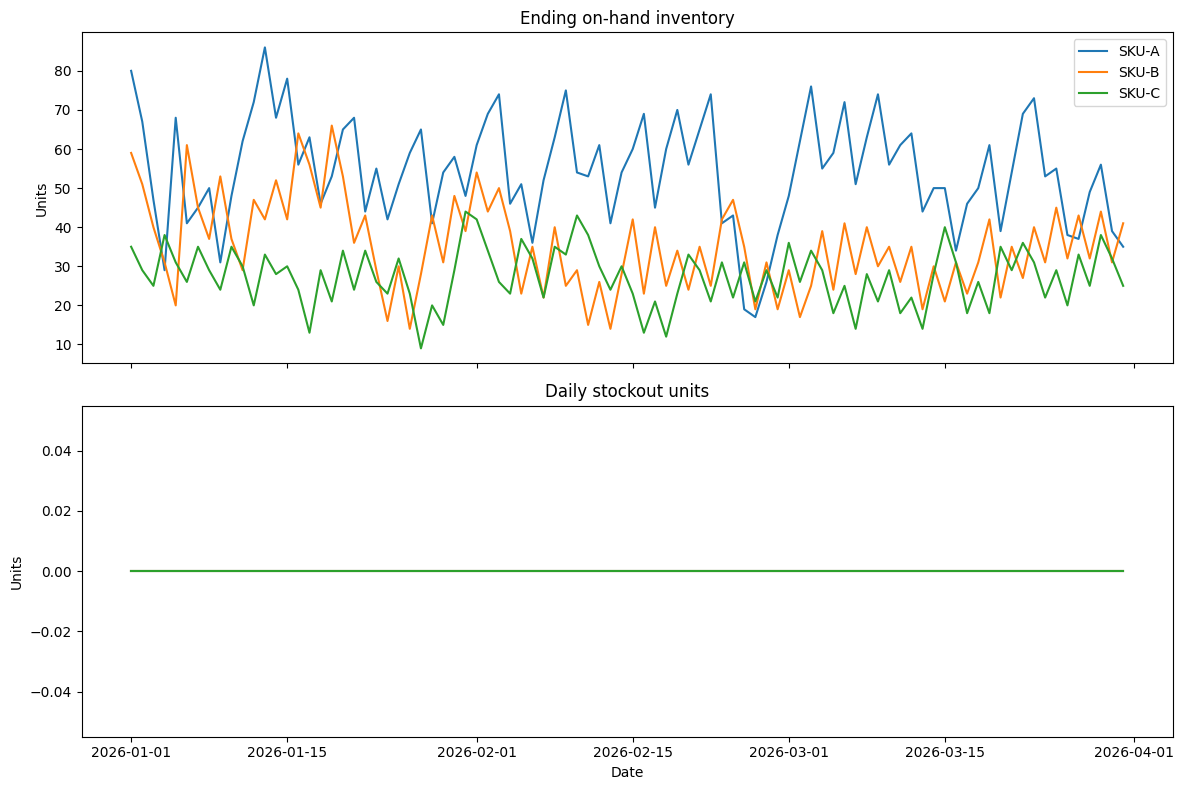

In [10]:
# Plot ending on-hand inventory and stockouts by SKU
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for sku in all_skus:
    temp = log_df[log_df['sku'] == sku]
    axes[0].plot(temp['date'], temp['on_hand_end'], label=sku)
    axes[1].plot(temp['date'], temp['stockout_units'], label=sku)
axes[0].set_title('Ending on-hand inventory')
axes[0].set_ylabel('Units')
axes[1].set_title('Daily stockout units')
axes[1].set_ylabel('Units')
axes[1].set_xlabel('Date')
axes[0].legend()
plt.tight_layout()
plt.show()


## Interpretation

The agent balances service and cost in three ways:

- Safety stock protects against EWMA forecast error and the specified service level.
- The projected-inventory check accounts for demand during the lead time and review period.
- The order-up-to rule and minimum order quantity prevent tiny, frequent purchase orders.

The fill rate is the share of total demand fulfilled immediately. Stockout cost penalizes unfilled units, while holding cost penalizes inventory remaining at the end of each day. Because variable purchase cost is included in the current simulation, total cost reflects the main trade-off between ordering enough to avoid stockouts and carrying too much inventory.

## Ethics, trust, and scaling note

The agent's goal is to minimize stockouts and total cost while maintaining the requested service level. Its inputs are demand history and EWMA forecast, on-hand stock, inventory in transit, lead time, minimum order quantity, costs, and service level. Its output is either a purchase order quantity or a transparent wait decision. Stockouts represent demand that could not be fulfilled immediately; fill rate is fulfilled demand divided by total demand; total cost combines holding, stockout, and order costs.

This transparency matters for trust: a manager can audit every decision in the daily log, see which assumptions triggered an order, and adjust the service level or inventory cap when business priorities change. The main trade-off is that more safety stock generally improves service reliability but ties up working capital and increases holding cost.

For production, the agent could run as a scheduled container or cloud job after daily sales data arrives. Monitoring should alert on declining fill rate, stockout spikes, unusual forecast error, stale data, and excessive inventory. Reliability controls should validate required columns and nonnegative quantities, handle missing dates as zero demand only when appropriate, and retry failed data loads or PO submissions with idempotent order IDs. Cost controls should enforce an inventory-position cap, track working capital, require approval for unusually large POs, and compare actual results with the baseline regularly.